In [24]:

#by Henry Schumacher
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
import time
start_setup = time.process_time_ns()
print('---------------------------------------')
print(time.strftime("pixe_cross.ipynb started: %a, %d %b %Y %H:%M:%S", time.localtime()))
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
import os
import sys
import json
import uuid
# import h5py
import math
import xraydb
import plotly
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
import numpy as np
import pandas as pd
# import pyxray as xy
# import odrpack as odr
import seaborn as sb
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
import matplotlib.pyplot as plt
from matplotlib import ticker
from matplotlib.gridspec import GridSpec
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from getmac import get_mac_address as gma
from itertools import chain
from matplotlib.offsetbox import OffsetImage, AnnotationBbox, TextArea, VPacker
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
from colors import load_colors
from PIXE_functions import *
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#

from matplotlib import rc
# rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
## for Palatino and other serif fonts use:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times"],
    "text.usetex": True,
    "font.size": 8,
    "pgf.rcfonts": False
})


plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "pgf.preamble": "\n".join([
          r'\usepackage{amsmath}',
     ]),
})

#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
color_schemes = load_colors()


end_setup = time.process_time_ns()
elapsed_setup = (end_setup - start_setup)/1e6

print(f'INFO: SETUP COMPLETE ({elapsed_setup:.2f} ms)')
print('---------------------------------------')
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#

---------------------------------------
pixe_cross.ipynb started: Tue, 03 Nov 2026 14:14:02
INFO: SETUP COMPLETE (15.62 ms)
---------------------------------------


In [30]:
full_pixe_data = read_json_formatted_file(filepath=".//elemental_data//pixe_cross_data.json")


In [41]:
def single_element_data_plot(data:dict, start_val:list, elem:str):
    DPI = 250
    
    data_x = np.array(data[elem]["energy"])
    data_y_ecpssr = np.array(data[elem]["ecpssr"])
    data_y_ref = np.array(data[elem]["reference"])
    print(data_x)
    print(data_y_ecpssr)
    print(data_y_ref)
    data_x_err = np.array([0.05]*len(data_x))
    data_y_err = np.array(data[elem]["error"]*data_y_ref)*0.01
    # beta = evaluator_scipy(func=poly4_func, beta0_list=start_val, x=data_x, y=data_y, xerr=data_x_err, yerr=data_y_err)
    # beta_export = [beta['param'],beta['errors']]
    # xlin = np.linspace(np.min(data_x), np.max(data_x), 2000)
    
    plt.figure(figsize=(6,4), dpi=DPI)
    plt.errorbar(data_x, data_y_ecpssr, xerr=data_x_err,fmt='s', zorder=2)
    plt.errorbar(data_x, data_y_ref, xerr=data_x_err, yerr=data_y_err,fmt='x', zorder=2)
    # plt.plot(xlin, poly4_func(beta_export[0],xlin))
    
    plt.xlabel('Energy / MeV')
    plt.ylabel('cross section / b')
    
    plt.ylim(1E5,1.1*max(np.max(data_y_ecpssr),np.max(data_y_ref)))
    plt.xlim(0.1,14)
    plt.yscale('log')
    plt.xscale('log')
    plt.grid(which='both', zorder=1)
    plt.show()
    return 'lol'

[0.5 0.7 1.  1.4 2.  3.  4.5]
[408100. 451900. 458700. 432500. 381600. 311700. 243200.]
[415800. 482000. 511900. 496900. 441600. 348000. 245100.]


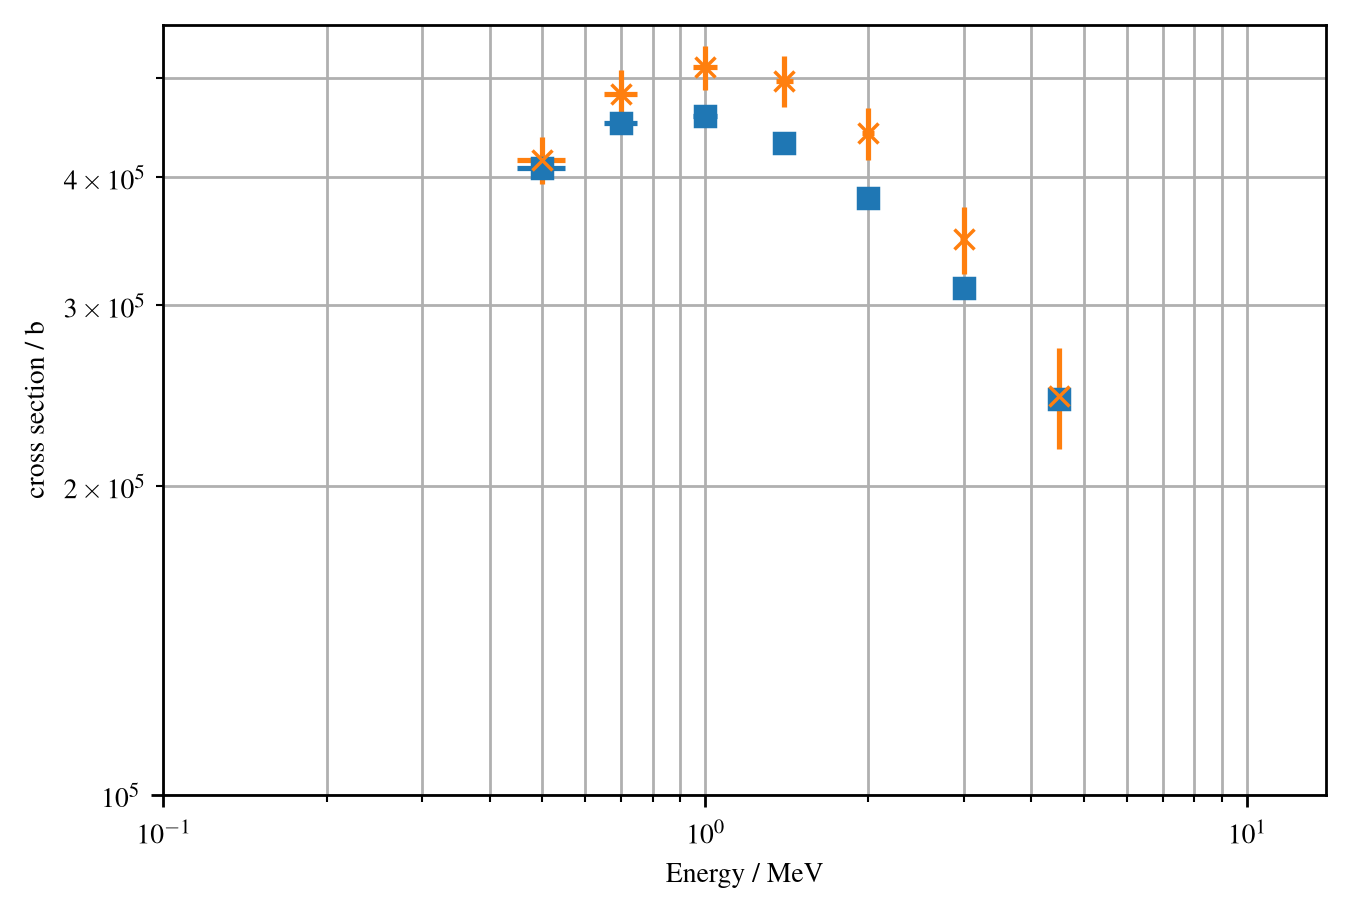

'lol'

In [43]:
s_val = [0,1,1,0,1]
single_element_data_plot(data=full_pixe_data, start_val=s_val, elem='N')